In [ ]:
!pip install scipy scikit-learn matplotlib torch --quiet
print('✅ Packages ready')

In [ ]:
import os, copy, random, warnings
import numpy as np
import scipy.io as sio
from scipy.io import loadmat
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, precision_score, recall_score, f1_score
)
import matplotlib.pyplot as plt
import pandas as pd
from collections import defaultdict
warnings.filterwarnings('ignore')

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print(f'✅ GPU: {torch.cuda.get_device_name(0)}')
    print(f'   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
    torch.backends.cudnn.benchmark = True  # speeds up training on fixed-size inputs
else:
    print('⚠️  No GPU — training will be slow. Enable GPU in Runtime > Change runtime type')

✅ GPU: Tesla T4
   Memory: 15.6 GB


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
base_path  = "/content/drive/MyDrive/ks20/KS20_Vislab_MultiView_dataset"
directions = ['frontal','left_lateral','right_lateral','left_diagonal','right_diagonal']

data = []
for d in directions:
    dpath = os.path.join(base_path, d)
    for file in os.listdir(dpath):
        if file.endswith('.mat'):
            subject_id = int(file.split('body')[1].split('.')[0])
            seq_id     = file.split('_')[0]
            data.append({'path': os.path.join(dpath, file),
                         'subject': subject_id, 'direction': d, 'seq': seq_id})

print(f'Total raw samples: {len(data)}')
sc = defaultdict(int)
for x in data: sc[x['subject']] += 1
print(f'Unique subjects: {len(sc)}  | Samples per subject: {list(sc.values())[0]} (all same? {len(set(sc.values()))==1})')

Total raw samples: 300
Unique subjects: 20  | Samples per subject: 15 (all same? True)


In [ ]:
def extract_xyz_from_joint(joint):
    pos = joint[2]
    return [float(np.asarray(pos[0][i]).item()) for i in range(3)]

def load_ks20_skeleton(mat_path):
    mat = loadmat(mat_path)
    gc  = mat['gc']
    frames = []
    for t in range(gc.shape[1]):
        try:
            frame = gc[0, t]
            body  = frame['body'][0, 0]
            jm    = body['joints']
            fj    = [extract_xyz_from_joint(jm[0, j]) for j in range(jm.shape[1])]
            if len(fj) == 25:
                frames.append(fj)
        except Exception:
            continue
    return np.array(frames, dtype=np.float32)

print(' Loader ready')

 Loader ready


In [ ]:
TARGET_LEN = 40

def normalize_seq_len(seq, T=TARGET_LEN):
    n = seq.shape[0]
    if n == T:   return seq
    if n > T:    return seq[np.linspace(0, n-1, T).astype(int)]
    pad = np.repeat(seq[-1:], T-n, axis=0)
    return np.concatenate([seq, pad], axis=0)

def center_skeleton(seq, root=0):
    return seq - seq[:, root:root+1, :]

def preprocess_sequence(mat_path):
    sk = load_ks20_skeleton(mat_path)
    if sk is None or sk.shape[0] == 0: return None
    sk = normalize_seq_len(sk)
    sk = center_skeleton(sk)
    return sk

processed_data = []
for item in data:
    sk = preprocess_sequence(item['path'])
    if sk is not None:
        processed_data.append({**item, 'skeleton': sk})

print(f'✅ Preprocessed: {len(processed_data)} samples')

✅ Preprocessed: 300 samples


In [ ]:
# KS20 bone connections: (parent, child)
BONES = [
    (0,1),(1,2),(2,3),          # spine -> neck -> head
    (2,4),(4,5),(5,6),(6,7),    # left arm
    (2,8),(8,9),(9,10),(10,11), # right arm
    (0,12),(12,13),(13,14),(14,15), # left leg
    (0,16),(16,17),(17,18),(18,19), # right leg
    (4,8),(12,16)               # shoulder link, hip link
]

# Joint angle triplets: (joint, parent, child) — angle at 'joint'
ANGLE_TRIPLETS = [
    (1,0,2),   # spine mid
    (2,1,3),   # neck
    (4,2,5),   # left shoulder
    (5,4,6),   # left elbow
    (8,2,9),   # right shoulder
    (9,8,10),  # right elbow
    (12,0,13), # left hip
    (13,12,14),# left knee
    (16,0,17), # right hip
    (17,16,18),# right knee
]

def compute_canonical_skeleton(seq):
    """
    Rotate skeleton to canonical orientation:
    1. Hip center at origin (already done by center_skeleton with root=0)
    2. Rotate so spine (0→2) points along +Y axis
    3. Rotate so shoulder axis (4→8) points along +X axis
    Returns normalized skeleton (T, 25, 3)
    """
    seq = seq.copy()
    eps = 1e-8

    # Use mean pose for computing rotation (more stable)
    mean_pose = seq.mean(axis=0)  # (25, 3)

    # Step 1: Align spine to Y-axis
    spine_vec = mean_pose[2] - mean_pose[0]  # neck - hip
    spine_vec = spine_vec / (np.linalg.norm(spine_vec) + eps)
    y_axis = np.array([0., 1., 0.], dtype=np.float32)
    v = np.cross(spine_vec, y_axis)
    s = np.linalg.norm(v)
    c = np.dot(spine_vec, y_axis)
    if s > eps:
        vx = np.array([[0,-v[2],v[1]],[v[2],0,-v[0]],[-v[1],v[0],0]], dtype=np.float32)
        R1 = np.eye(3, dtype=np.float32) + vx + vx@vx * ((1-c)/(s*s+eps))
    else:
        R1 = np.eye(3, dtype=np.float32) * (1 if c > 0 else -1)

    seq = seq @ R1.T
    mean_pose = mean_pose @ R1.T

    # Step 2: Align shoulder axis to X-axis (yaw correction)
    shoulder_vec = mean_pose[8] - mean_pose[4]  # right - left
    angle = np.arctan2(shoulder_vec[2], shoulder_vec[0])
    c2, s2 = np.cos(-angle), np.sin(-angle)
    R2 = np.array([[c2,0,s2],[0,1,0],[-s2,0,c2]], dtype=np.float32)
    seq = seq @ R2.T

    return seq.astype(np.float32)


def compute_bone_features(seq, eps=1e-8):
    """
    Compute per-frame bone vectors and normalize by bone length.
    Returns shape (T, len(BONES)*4) — unit vector + length per bone
    """
    T = seq.shape[0]
    features = []
    for p, c in BONES:
        vec = seq[:, c, :] - seq[:, p, :]  # (T, 3)
        length = np.linalg.norm(vec, axis=1, keepdims=True)  # (T, 1)
        unit = vec / (length + eps)  # (T, 3)
        features.append(unit)   # unit direction
        features.append(length) # magnitude
    return np.concatenate(features, axis=1).astype(np.float32)  # (T, 84)


def compute_joint_angles(seq, eps=1e-8):
    """
    Compute angle at each joint in ANGLE_TRIPLETS.
    angle = arccos(dot(v1, v2)) where v1,v2 are normalized incoming/outgoing bones
    Returns shape (T, len(ANGLE_TRIPLETS))
    """
    T = seq.shape[0]
    angles = []
    for j, p, c in ANGLE_TRIPLETS:
        v1 = seq[:, p, :] - seq[:, j, :]  # incoming
        v2 = seq[:, c, :] - seq[:, j, :]  # outgoing
        v1 = v1 / (np.linalg.norm(v1, axis=1, keepdims=True) + eps)
        v2 = v2 / (np.linalg.norm(v2, axis=1, keepdims=True) + eps)
        dot = np.clip((v1 * v2).sum(axis=1), -1.0, 1.0)
        angles.append(np.arccos(dot)[:, np.newaxis])
    return np.concatenate(angles, axis=1).astype(np.float32)  # (T, 10)


def compute_motion_features(seq, eps=1e-8):
    """
    Temporal velocity + acceleration magnitude per joint.
    Returns shape (T, 25*2) — padded to match T
    """
    vel = np.diff(seq, axis=0)       # (T-1, 25, 3)
    vel_mag = np.linalg.norm(vel, axis=2)  # (T-1, 25)
    # pad front
    vel_mag = np.concatenate([vel_mag[:1], vel_mag], axis=0)  # (T, 25)

    acc = np.diff(vel_mag, axis=0)   # (T-1, 25)
    acc = np.concatenate([acc[:1], acc], axis=0)  # (T, 25)

    return np.concatenate([vel_mag, acc], axis=1).astype(np.float32)  # (T, 50)


def build_input_tensor(seq):
    """
    Build the full input for the model from a preprocessed skeleton.
    1. Apply canonical normalization
    2. Compute bone features (T, 84)
    3. Compute joint angles (T, 10)
    4. Compute motion features (T, 50)
    5. Concatenate → (T, 144)
    Also return the canonical skeleton for raw-coord branch.
    """
    canon = compute_canonical_skeleton(seq)   # (T, 25, 3)
    bones  = compute_bone_features(canon)     # (T, 84)
    angles = compute_joint_angles(canon)      # (T, 10)
    motion = compute_motion_features(canon)   # (T, 50)
    feat   = np.concatenate([bones, angles, motion], axis=1)  # (T, 144)
    return canon, feat


# Test
canon_test, feat_test = build_input_tensor(processed_data[0]['skeleton'])
print(f'✅ Canonical skeleton: {canon_test.shape}')
print(f'   Bone+angle+motion features: {feat_test.shape}  (view-invariant input)')

✅ Canonical skeleton: (40, 25, 3)
   Bone+angle+motion features: (40, 144)  (view-invariant input)


In [ ]:
def compute_anthropometric_features(seq, eps=1e-6):
    def dist(a, b): return np.linalg.norm(a - b, axis=-1)
    sb=seq[:,0]; nk=seq[:,2]
    ls=seq[:,4]; le=seq[:,5]; lw=seq[:,6]
    rs=seq[:,8]; re=seq[:,9]; rw=seq[:,10]
    lh=seq[:,12]; lk=seq[:,13]; la=seq[:,14]
    rh=seq[:,16]; rk=seq[:,17]; ra=seq[:,18]
    sw=dist(ls,rs).mean(); hw=dist(lh,rh).mean(); tm=dist(nk,sb).mean()
    la_=( dist(ls,le)+dist(le,lw) ).mean(); ra_=( dist(rs,re)+dist(re,rw) ).mean()
    ll_=( dist(lh,lk)+dist(lk,la) ).mean(); rl_=( dist(rh,rk)+dist(rk,ra) ).mean()
    kw=dist(lk,rk).mean(); aw=dist(la,ra).mean()
    avg_arm=(la_+ra_)/2; avg_leg=(ll_+rl_)/2
    return np.array([sw,hw,tm,la_,ra_,ll_,rl_,kw,aw,
                     sw/(hw+eps),tm/(avg_leg+eps),avg_arm/(avg_leg+eps),
                     abs(la_-ra_),abs(ll_-rl_)], dtype=np.float32)

def compute_gait_features(seq, eps=1e-6):
    if seq is None or seq.shape[0] < 3: return np.zeros(15, dtype=np.float32)
    vel=np.diff(seq,axis=0); speed=np.linalg.norm(vel,axis=2)
    acc=np.diff(vel,axis=0); acc_mag=np.linalg.norm(acc,axis=2)
    upper=[4,5,6,8,9,10,2,3]; lower=[12,13,14,16,17,18,0,1]
    la=seq[:,14]; ra=seq[:,18]; lw=seq[:,6]; rw=seq[:,10]
    sb=seq[:,0]; nk=seq[:,2]
    ad=np.linalg.norm(la-ra,axis=1)
    peaks=sum(1 for i in range(1,len(ad)-1) if ad[i]>ad[i-1] and ad[i]>ad[i+1])
    return np.array([
        speed.mean(), speed[:,lower].mean(), speed[:,upper].mean(),
        speed.mean(), speed.var(),
        acc_mag.mean() if acc_mag.size>0 else 0.,
        ad.mean(), ad.std(),
        np.abs(np.diff(la[:,2])).mean(),
        peaks/(len(ad)/2.+eps),
        np.linalg.norm(np.diff(la,axis=0),axis=1).mean(),
        np.linalg.norm(np.diff(ra,axis=0),axis=1).mean(),
        np.linalg.norm(np.diff(lw,axis=0),axis=1).mean(),
        np.linalg.norm(np.diff(rw,axis=0),axis=1).mean(),
        ((sb[:,0]+nk[:,0])/2).std()
    ], dtype=np.float32)

def compute_shape_features(seq, eps=1e-6):
    if seq is None or seq.shape[0]==0: return np.zeros(16, dtype=np.float32)
    def dist(a,b): return np.linalg.norm(a-b,axis=-1)
    sb=seq[:,0]; sm=seq[:,1]; nk=seq[:,2]; hd=seq[:,3]
    ls=seq[:,4]; le=seq[:,5]; lw=seq[:,6]
    rs=seq[:,8]; re=seq[:,9]; rw=seq[:,10]
    lh=seq[:,12]; lk=seq[:,13]; la=seq[:,14]
    rh=seq[:,16]; rk=seq[:,17]; ra=seq[:,18]
    sw=dist(ls,rs).mean(); hw=dist(lh,rh).mean(); torso=dist(nk,sb).mean()
    spine=(dist(sm,sb)+dist(nk,sm)).mean(); hn=dist(hd,nk).mean()
    larm=(dist(ls,le)+dist(le,lw)).mean(); rarm=(dist(rs,re)+dist(re,rw)).mean()
    lleg=(dist(lh,lk)+dist(lk,la)).mean(); rleg=(dist(rh,rk)+dist(rk,ra)).mean()
    aa=(larm+rarm)/2; al=(lleg+rleg)/2
    lsrh=dist(ls,rh).mean(); rslh=dist(rs,lh).mean()
    return np.array([sw,hw,torso,spine,hn,larm,rarm,lleg,rleg,lsrh,rslh,
                     sw/(hw+eps),torso/(al+eps),aa/(al+eps),hn/(torso+eps),
                     abs(larm-rarm)+abs(lleg-rleg)+abs(lsrh-rslh)], dtype=np.float32)

# Compute all features on canonical skeletons
for item in processed_data:
    canon, feat = build_input_tensor(item['skeleton'])
    item['canon']   = canon
    item['feat']    = feat       # (T, 144) view-invariant
    item['anthro']  = compute_anthropometric_features(canon)
    item['gait']    = compute_gait_features(canon)
    item['shape']   = compute_shape_features(canon)

print(f'✅ All features computed')
print(f'   canon: {processed_data[0]["canon"].shape}')
print(f'   feat:  {processed_data[0]["feat"].shape}  (bone+angle+motion)')
print(f'   anthro/gait/shape: {processed_data[0]["anthro"].shape}/{processed_data[0]["gait"].shape}/{processed_data[0]["shape"].shape}')

✅ All features computed
   canon: (40, 25, 3)
   feat:  (40, 144)  (bone+angle+motion)
   anthro/gait/shape: (14,)/(15,)/(16,)


In [ ]:
all_subject_ids = sorted(set(x['subject'] for x in processed_data))
label_map  = {sid: idx for idx, sid in enumerate(all_subject_ids)}
num_classes = len(label_map)
print(f'✅ {num_classes} classes: {all_subject_ids}')

✅ 20 classes: [1, 2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 16, 17, 19, 20, 21, 22, 23, 24]


In [ ]:
def aug_noise(seq, sigma=0.004):
    return seq + np.random.randn(*seq.shape).astype(np.float32) * sigma

def aug_rotate(seq, deg=10):
    """Small rotation AFTER canonical alignment — simulates imperfect alignment"""
    a = np.radians(np.random.uniform(-deg, deg))
    c, s = np.cos(a), np.sin(a)
    R = np.array([[c,0,s],[0,1,0],[-s,0,c]], dtype=np.float32)
    return seq @ R.T

def aug_scale(seq, lo=0.92, hi=1.08):
    return seq * np.random.uniform(lo, hi)

def aug_flip(seq):
    s = seq.copy()
    for l, r in [(4,8),(5,9),(6,10),(7,11),(12,16),(13,17),(14,18),(15,19)]:
        s[:,l,:], s[:,r,:] = seq[:,r,:].copy(), seq[:,l,:].copy()
    s[:,:,0] *= -1
    return s

def aug_timewarp(seq, sigma=0.10):
    T = seq.shape[0]
    orig = np.arange(T)
    kx = np.linspace(0, T-1, 5)
    ky = np.random.randn(5) * sigma * T
    warp = np.interp(orig, kx, ky)
    new  = np.clip(orig + warp, 0, T-1)
    return np.stack([np.interp(new, orig, seq[:,j,c])
                     for j in range(seq.shape[1])
                     for c in range(seq.shape[2])], axis=1
                    ).reshape(T, seq.shape[1], seq.shape[2]).astype(np.float32)

def aug_crop(seq, lo=0.82, hi=0.95):
    T = seq.shape[0]
    k = int(T * np.random.uniform(lo, hi))
    st = np.random.randint(0, T-k)
    return seq[np.linspace(0, k-1, T).astype(int) + st]

def aug_shear(seq, max_s=0.06):
    """Random shear along XZ plane — distorts body proportions slightly"""
    sx = np.random.uniform(-max_s, max_s)
    sz = np.random.uniform(-max_s, max_s)
    S  = np.array([[1,0,sx],[0,1,0],[sz,0,1]], dtype=np.float32)
    return seq @ S.T

def aug_dropout(seq, p=0.04):
    s = seq.copy()
    s[np.random.rand(*s.shape[:2]) < p] = 0.0
    return s

AUGMENTATIONS = [
    ('noise',    lambda s: aug_noise(s)),
    ('rotate',   lambda s: aug_rotate(s)),
    ('scale',    lambda s: aug_scale(s)),
    ('flip',     aug_flip),
    ('timewarp', aug_timewarp),
    ('crop',     aug_crop),
    ('shear',    aug_shear),
    ('dropout',  aug_dropout),
    # combos — multiply data further
    ('noise+rotate', lambda s: aug_rotate(aug_noise(s), deg=8)),
    ('scale+flip',   lambda s: aug_flip(aug_scale(s))),
    ('timewarp+noise', lambda s: aug_noise(aug_timewarp(s), sigma=0.003)),
]

print(f'✅ {len(AUGMENTATIONS)} augmentations ready (×{len(AUGMENTATIONS)+1} data expansion)')

✅ 11 augmentations ready (×12 data expansion)


In [ ]:
def aug_noise(seq, sigma=0.004):
    return seq + np.random.randn(*seq.shape).astype(np.float32) * sigma

def aug_rotate(seq, deg=10):
    """Small rotation AFTER canonical alignment — simulates imperfect alignment"""
    a = np.radians(np.random.uniform(-deg, deg))
    c, s = np.cos(a), np.sin(a)
    R = np.array([[c,0,s],[0,1,0],[-s,0,c]], dtype=np.float32)
    return seq @ R.T

def aug_scale(seq, lo=0.92, hi=1.08):
    return seq * np.random.uniform(lo, hi)

def aug_flip(seq):
    s = seq.copy()
    for l, r in [(4,8),(5,9),(6,10),(7,11),(12,16),(13,17),(14,18),(15,19)]:
        s[:,l,:], s[:,r,:] = seq[:,r,:].copy(), seq[:,l,:].copy()
    s[:,:,0] *= -1
    return s

def aug_timewarp(seq, sigma=0.10):
    T = seq.shape[0]
    orig = np.arange(T)
    kx = np.linspace(0, T-1, 5)
    ky = np.random.randn(5) * sigma * T
    warp = np.interp(orig, kx, ky)
    new  = np.clip(orig + warp, 0, T-1)
    return np.stack([np.interp(new, orig, seq[:,j,c])
                     for j in range(seq.shape[1])
                     for c in range(seq.shape[2])], axis=1
                    ).reshape(T, seq.shape[1], seq.shape[2]).astype(np.float32)

def aug_crop(seq, lo=0.82, hi=0.95):
    T = seq.shape[0]
    k = int(T * np.random.uniform(lo, hi))
    st = np.random.randint(0, T-k)
    return seq[np.linspace(0, k-1, T).astype(int) + st]

def aug_shear(seq, max_s=0.06):
    """Random shear along XZ plane — distorts body proportions slightly"""
    sx = np.random.uniform(-max_s, max_s)
    sz = np.random.uniform(-max_s, max_s)
    S  = np.array([[1,0,sx],[0,1,0],[sz,0,1]], dtype=np.float32)
    return seq @ S.T

def aug_dropout(seq, p=0.04):
    s = seq.copy()
    s[np.random.rand(*s.shape[:2]) < p] = 0.0
    return s

AUGMENTATIONS = [
    ('noise',    lambda s: aug_noise(s)),
    ('rotate',   lambda s: aug_rotate(s)),
    ('scale',    lambda s: aug_scale(s)),
    ('flip',     aug_flip),
    ('timewarp', aug_timewarp),
    ('crop',     aug_crop),
    ('shear',    aug_shear),
    ('dropout',  aug_dropout),
    # combos — multiply data further
    ('noise+rotate', lambda s: aug_rotate(aug_noise(s), deg=8)),
    ('scale+flip',   lambda s: aug_flip(aug_scale(s))),
    ('timewarp+noise', lambda s: aug_noise(aug_timewarp(s), sigma=0.003)),
]

print(f'✅ {len(AUGMENTATIONS)} augmentations ready (×{len(AUGMENTATIONS)+1} data expansion)')

✅ 11 augmentations ready (×12 data expansion)


In [ ]:
FEAT_DIM = 144  # bone(84) + angles(10) + motion(50)

class PersonIDDataset(Dataset):
    def __init__(self, samples, label_map, runtime_aug=False):
        self.samples     = samples
        self.label_map   = label_map
        self.runtime_aug = runtime_aug

    def __len__(self):
        return len(self.samples)

    def _light_aug(self, canon):
        if np.random.rand() < 0.5: canon = aug_noise(canon, sigma=0.003)
        if np.random.rand() < 0.3: canon = aug_scale(canon, 0.95, 1.05)
        if np.random.rand() < 0.2: canon = aug_rotate(canon, deg=5)
        return canon

    def __getitem__(self, idx):
        item  = self.samples[idx]
        canon = item['canon'].copy()

        if self.runtime_aug:
            canon = self._light_aug(canon)
            # Recompute features for runtime aug
            bones  = compute_bone_features(canon)
            angles = compute_joint_angles(canon)
            motion = compute_motion_features(canon)
            feat   = np.concatenate([bones, angles, motion], axis=1)
        else:
            feat = item['feat']

        return (
            torch.tensor(feat,         dtype=torch.float32),  # (T, 144)
            torch.tensor(canon,        dtype=torch.float32),  # (T, 25, 3)
            torch.tensor(item['anthro'], dtype=torch.float32),
            torch.tensor(item['gait'],   dtype=torch.float32),
            torch.tensor(item['shape'],  dtype=torch.float32),
            torch.tensor(self.label_map[item['subject']], dtype=torch.long)
        )

print('✅ Dataset class ready')

✅ Dataset class ready


In [ ]:
# ── 1D Temporal CNN encoder (fast, local motion patterns) ────────────────────
class TemporalCNNEncoder(nn.Module):
    def __init__(self, in_dim=FEAT_DIM, out_dim=128, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            # input: (B, T, in_dim) → permute → (B, in_dim, T)
            nn.Conv1d(in_dim, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(dropout),

            nn.Conv1d(128, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(dropout),

            nn.Conv1d(128, out_dim, kernel_size=7, padding=3),
            nn.BatchNorm1d(out_dim), nn.GELU(),
        )

    def forward(self, x):
        # x: (B, T, in_dim)
        x = x.permute(0, 2, 1)  # (B, in_dim, T)
        x = self.net(x)          # (B, out_dim, T)
        return x.mean(dim=2)     # (B, out_dim) — temporal average


# ── Compact Transformer encoder ───────────────────────────────────────────────
class CompactTransformer(nn.Module):
    def __init__(self, in_dim=FEAT_DIM, embed_dim=128,
                 num_heads=4, num_layers=2, dropout=0.4):
        super().__init__()
        self.proj = nn.Linear(in_dim, embed_dim)
        self.pos  = nn.Parameter(torch.randn(1, TARGET_LEN, embed_dim) * 0.01)
        enc = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=embed_dim*2, dropout=dropout,
            batch_first=True, activation='gelu'
        )
        self.transformer = nn.TransformerEncoder(enc, num_layers=num_layers)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.proj(x) + self.pos[:, :x.size(1), :]
        x = self.transformer(x)
        x = self.norm(x)
        return x.mean(dim=1)  # (B, embed_dim)


# ── ST-GCN (2-block, lightweight) ────────────────────────────────────────────
class KS20Graph:
    def __init__(self):
        N = 25
        slinks = [(i,i) for i in range(N)]
        elinks = [(0,1),(1,2),(2,3),(2,4),(4,5),(5,6),(6,7),
                  (2,8),(8,9),(9,10),(10,11),(0,12),(12,13),(13,14),(14,15),
                  (0,16),(16,17),(17,18),(18,19),(4,8),(12,16)]
        A = np.zeros((N,N), dtype=np.float32)
        for i,j in slinks+elinks:
            A[i,j]=A[j,i]=1.0
        D = np.diag(1./np.sqrt(A.sum(1)+1e-6))
        self.A = torch.tensor(D@A@D, dtype=torch.float32)

class GCNBlock(nn.Module):
    def __init__(self, ic, oc, dropout=0.4):
        super().__init__()
        self.gcn = nn.Conv2d(ic, oc, 1)
        self.tcn = nn.Sequential(
            nn.BatchNorm2d(oc), nn.GELU(),
            nn.Conv2d(oc, oc, (9,1), stride=(1,1), padding=(4,0)),
            nn.BatchNorm2d(oc), nn.Dropout(dropout)
        )
        self.res = nn.Identity() if ic==oc else nn.Sequential(
            nn.Conv2d(ic,oc,1), nn.BatchNorm2d(oc))
        self.relu = nn.GELU()

    def forward(self, x, A):
        r = self.res(x)
        x = self.gcn(torch.einsum('bctv,vw->bctw', x, A))
        x = self.tcn(x)
        return self.relu(x + r)

class STGCNBranch(nn.Module):
    def __init__(self, out_dim=128, dropout=0.4):
        super().__init__()
        g = KS20Graph()
        self.register_buffer('A', g.A)
        self.bn  = nn.BatchNorm1d(75)
        self.b1  = GCNBlock(3, 64, dropout)
        self.b2  = GCNBlock(64, out_dim, dropout)
        self.proj = nn.Linear(out_dim, out_dim)

    def forward(self, x):  # x: (B,T,25,3)
        B,T,V,C = x.shape
        x = self.bn(x.reshape(B,T,75).transpose(1,2)).transpose(1,2)
        x = x.reshape(B,T,V,C).permute(0,3,1,2)  # (B,3,T,V)
        x = self.b2(self.b1(x, self.A), self.A)
        x = x.mean(dim=-1).mean(dim=-1)  # (B, out_dim) global average
        return self.proj(x)


# ── Statistical feature encoder ───────────────────────────────────────────────
class StatEncoder(nn.Module):
    def __init__(self, idim, odim=64, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(idim, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(128, odim), nn.GELU()
        )
    def forward(self, x): return self.net(x)


# ── Gated multi-stream fusion ─────────────────────────────────────────────────
class GatedFusion(nn.Module):
    """
    Learns a gate vector for each stream based on ALL streams combined.
    More expressive than simple attention.
    """
    def __init__(self, stream_dims, out_dim=128):
        super().__init__()
        total = sum(stream_dims)
        self.gates = nn.Sequential(
            nn.Linear(total, 256), nn.GELU(),
            nn.Linear(256, len(stream_dims)),
            nn.Softmax(dim=1)
        )
        # project each stream to same dim
        self.projs = nn.ModuleList([
            nn.Linear(d, out_dim) for d in stream_dims
        ])
        self.out_norm = nn.LayerNorm(out_dim)

    def forward(self, streams):
        cat = torch.cat(streams, dim=1)
        g   = self.gates(cat)  # (B, n_streams)
        proj_streams = [self.projs[i](s) for i,s in enumerate(streams)]
        stacked = torch.stack(proj_streams, dim=1)  # (B, n, out_dim)
        fused   = (g.unsqueeze(-1) * stacked).sum(dim=1)
        return self.out_norm(fused), g


# ── Full v3 model ─────────────────────────────────────────────────────────────
class PersonIDv3(nn.Module):
    def __init__(self, num_classes, embed_dim=128, dropout=0.4):
        super().__init__()
        D = embed_dim

        # 3 parallel skeleton encoders
        self.cnn_enc   = TemporalCNNEncoder(FEAT_DIM, D, dropout)
        self.trans_enc = CompactTransformer(FEAT_DIM, D, num_heads=4, num_layers=2, dropout=dropout)
        self.stgcn_enc = STGCNBranch(D, dropout)

        # statistical feature encoders
        self.anthro_enc = StatEncoder(14, 64, dropout)
        self.gait_enc   = StatEncoder(15, 64, dropout)
        self.shape_enc  = StatEncoder(16, 64, dropout)
        # concat stat features
        self.stat_proj  = nn.Sequential(
            nn.Linear(64*3, D), nn.LayerNorm(D), nn.GELU(), nn.Dropout(dropout)
        )

        # gated fusion of 4 streams
        self.fusion = GatedFusion([D, D, D, D], out_dim=D)

        # embedding head (for triplet loss)
        self.embed_head = nn.Sequential(
            nn.Linear(D, D), nn.LayerNorm(D), nn.GELU(), nn.Dropout(dropout)
        )

        # classifier
        self.classifier = nn.Sequential(
            nn.Linear(D, 256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, feat, canon, anthro, gait, shape):
        # feat: (B,T,144), canon: (B,T,25,3)
        s1 = self.cnn_enc(feat)    # (B, D)
        s2 = self.trans_enc(feat)  # (B, D)
        s3 = self.stgcn_enc(canon) # (B, D)

        a  = self.anthro_enc(anthro)
        g  = self.gait_enc(gait)
        sh = self.shape_enc(shape)
        s4 = self.stat_proj(torch.cat([a, g, sh], dim=1))  # (B, D)

        fused, gates = self.fusion([s1, s2, s3, s4])
        emb  = self.embed_head(fused)        # (B, D)
        logits = self.classifier(emb)        # (B, num_classes)

        return logits, F.normalize(emb, dim=1), gates


# Verify
_m = PersonIDv3(num_classes).to(device)
_f = torch.randn(2, TARGET_LEN, FEAT_DIM).to(device)
_c = torch.randn(2, TARGET_LEN, 25, 3).to(device)
_a = torch.randn(2,14).to(device); _g=torch.randn(2,15).to(device); _s=torch.randn(2,16).to(device)
_out, _emb, _gates = _m(_f,_c,_a,_g,_s)
print(f'✅ Model OK — logits: {_out.shape}, emb: {_emb.shape}, gates: {_gates.shape}')
print(f'   Parameters: {sum(p.numel() for p in _m.parameters()):,}')
del _m,_f,_c,_a,_g,_s,_out,_emb,_gates

✅ Model OK — logits: torch.Size([2, 20]), emb: torch.Size([2, 128]), gates: torch.Size([2, 4])
   Parameters: 1,072,174


In [ ]:
class HardTripletLoss(nn.Module):
    """Online hard triplet mining loss."""
    def __init__(self, margin=0.3):
        super().__init__()
        self.margin = margin

    def forward(self, embeddings, labels):
        B = embeddings.size(0)
        # pairwise distances
        dist = torch.cdist(embeddings, embeddings, p=2)  # (B, B)

        labels = labels.unsqueeze(1)  # (B, 1)
        pos_mask = (labels == labels.T).float()  # (B, B)
        neg_mask = (labels != labels.T).float()

        # hardest positive
        pos_dist = dist * pos_mask + (1 - pos_mask) * (-1e9)
        hard_pos = pos_dist.max(dim=1)[0]

        # hardest negative
        neg_dist = dist * neg_mask + (1 - neg_mask) * 1e9
        hard_neg = neg_dist.min(dim=1)[0]

        loss = F.relu(hard_pos - hard_neg + self.margin)
        return loss.mean()


class CombinedLoss(nn.Module):
    def __init__(self, num_classes, triplet_weight=0.3, label_smoothing=0.05):
        super().__init__()
        self.ce      = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        self.triplet = HardTripletLoss(margin=0.3)
        self.tw      = triplet_weight

    def forward(self, logits, embeddings, labels):
        ce_loss  = self.ce(logits, labels)
        tri_loss = self.triplet(embeddings, labels)
        return ce_loss + self.tw * tri_loss, ce_loss.item(), tri_loss.item()

print('✅ Triplet + CE combined loss ready')

✅ Triplet + CE combined loss ready


In [ ]:
def mixup_batch(feat, canon, anthro, gait, shape, labels, alpha=0.2):
    """Mixup augmentation: blend two samples"""
    if alpha <= 0 or np.random.rand() > 0.5:
        return feat, canon, anthro, gait, shape, labels, labels, 1.0
    lam   = np.random.beta(alpha, alpha)
    idx   = torch.randperm(feat.size(0), device=feat.device)
    return (feat*lam + feat[idx]*(1-lam),
            canon*lam + canon[idx]*(1-lam),
            anthro*lam + anthro[idx]*(1-lam),
            gait*lam + gait[idx]*(1-lam),
            shape*lam + shape[idx]*(1-lam),
            labels, labels[idx], lam)


def train_one_epoch(model, loader, criterion, optimizer, device, use_mixup=True):
    model.train()
    tot_loss=0.; correct=0; total=0
    for feat,canon,anthro,gait,shape,lbl in loader:
        feat=feat.to(device); canon=canon.to(device)
        anthro=anthro.to(device); gait=gait.to(device)
        shape=shape.to(device); lbl=lbl.to(device)

        if use_mixup:
            feat,canon,anthro,gait,shape,lbl_a,lbl_b,lam = mixup_batch(
                feat,canon,anthro,gait,shape,lbl)
        else:
            lbl_a = lbl_b = lbl; lam = 1.0

        optimizer.zero_grad()
        logits, emb, _ = model(feat,canon,anthro,gait,shape)

        loss_a, _, _ = criterion(logits, emb, lbl_a)
        loss_b, _, _ = criterion(logits, emb, lbl_b)
        loss = lam * loss_a + (1-lam) * loss_b

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        tot_loss += loss.item() * lbl.size(0)
        preds = logits.argmax(1)
        correct += (preds == lbl).sum().item()
        total   += lbl.size(0)

    return tot_loss/total, correct/total


def evaluate(model, loader, criterion, device):
    model.eval()
    tot_loss=0.; correct=0; total=0
    all_preds=[]; all_labels=[]
    with torch.no_grad():
        for feat,canon,anthro,gait,shape,lbl in loader:
            feat=feat.to(device); canon=canon.to(device)
            anthro=anthro.to(device); gait=gait.to(device)
            shape=shape.to(device); lbl=lbl.to(device)
            logits, emb, _ = model(feat,canon,anthro,gait,shape)
            loss,_,_ = criterion(logits,emb,lbl)
            tot_loss += loss.item()*lbl.size(0)
            preds = logits.argmax(1)
            correct += (preds==lbl).sum().item()
            total   += lbl.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(lbl.cpu().numpy())
    return tot_loss/total, correct/total, all_preds, all_labels


def evaluate_tta(model, test_data, label_map, device, n_aug=8):
    """
    Test-Time Augmentation: average logits over n_aug augmented versions.
    Typically adds 2-5% accuracy.
    """
    model.eval()
    tta_augs = [
        lambda s: s,                            # original
        aug_flip,
        lambda s: aug_noise(s, 0.003),
        lambda s: aug_rotate(s, 8),
        lambda s: aug_scale(s, 0.93, 1.07),
        lambda s: aug_rotate(aug_flip(s), 5),
        lambda s: aug_noise(aug_rotate(s, 5), 0.002),
        lambda s: aug_scale(aug_noise(s, 0.002), 0.95, 1.05),
    ][:n_aug]

    all_logits  = []
    all_labels_list = []

    # Build base dataset
    ds = PersonIDDataset(test_data, label_map, runtime_aug=False)

    with torch.no_grad():
        for i in range(len(ds)):
            feat0, canon0, anthro0, gait0, shape0, lbl = ds[i]
            canon_np = canon0.numpy()

            logit_sum = None
            for aug_fn in tta_augs:
                aug_canon = aug_fn(canon_np.copy())
                bones  = compute_bone_features(aug_canon)
                angles = compute_joint_angles(aug_canon)
                motion = compute_motion_features(aug_canon)
                aug_feat = np.concatenate([bones,angles,motion],axis=1)

                f_t = torch.tensor(aug_feat,  dtype=torch.float32).unsqueeze(0).to(device)
                c_t = torch.tensor(aug_canon, dtype=torch.float32).unsqueeze(0).to(device)
                a_t = anthro0.unsqueeze(0).to(device)
                g_t = gait0.unsqueeze(0).to(device)
                s_t = shape0.unsqueeze(0).to(device)

                logits, _, _ = model(f_t, c_t, a_t, g_t, s_t)
                logit_sum = logits if logit_sum is None else logit_sum + logits

            all_logits.append((logit_sum / n_aug).squeeze(0))
            all_labels_list.append(lbl.item())

    logits_tensor = torch.stack(all_logits)
    preds = logits_tensor.argmax(1).cpu().numpy()
    return preds, all_labels_list


print('✅ Training loops + TTA ready')

✅ Training loops + TTA ready


In [ ]:
# Hyperparameters
NUM_EPOCHS   = 200
BATCH_SIZE   = 48   # larger batch → better triplet mining
EMBED_DIM    = 128
LR           = 2e-4
WEIGHT_DECAY = 1e-3
PATIENCE     = 60

test_seq_map = {0:'gc1', 1:'gc2', 2:'gc3'}

# Build raw folds
seq_folds_raw = [{'train':[], 'test':[]} for _ in range(3)]
for item in processed_data:
    for fi in range(3):
        if item['seq'] == test_seq_map[fi]: seq_folds_raw[fi]['test'].append(item)
        else: seq_folds_raw[fi]['train'].append(item)

print('Raw fold sizes:')
for i,f in enumerate(seq_folds_raw):
    print(f'  Fold {i+1}: train={len(f["train"])} test={len(f["test"])}')

Raw fold sizes:
  Fold 1: train=200 test=100
  Fold 2: train=200 test=100
  Fold 3: train=200 test=100


In [ ]:
def synthesize_dataset(raw_data, augmentations):
    augmented_data = []
    for item in raw_data:
        # Add original item
        augmented_data.append({**item, 'aug': 'original'})

        # Add augmented versions
        for aug_name, aug_fn in augmentations:
            # Use the original skeleton to apply augmentation
            augmented_skeleton = aug_fn(item['skeleton'].copy())

            # Recompute canonical form and features for the augmented skeleton
            canon, feat = build_input_tensor(augmented_skeleton)
            anthro = compute_anthropometric_features(canon)
            gait = compute_gait_features(canon)
            shape = compute_shape_features(canon)

            augmented_item = {
                **item,
                'skeleton': augmented_skeleton, # Store augmented skeleton
                'canon': canon,
                'feat': feat,
                'anthro': anthro,
                'gait': gait,
                'shape': shape,
                'aug': aug_name # Label the augmentation type
            }
            augmented_data.append(augmented_item)
    return augmented_data

def prepare_fold(fold_raw, augmentations=AUGMENTATIONS):
    """Augment train, scale both, return ready-to-use dicts."""
    train_aug  = synthesize_dataset(copy.deepcopy(fold_raw['train']), augmentations)
    test_clean = copy.deepcopy(fold_raw['test'])

    # Fit scalers on original training samples only
    orig = [x for x in train_aug if x.get('aug','original')=='original']
    sa = StandardScaler().fit(np.array([x['anthro'] for x in orig]))
    sg = StandardScaler().fit(np.array([x['gait']   for x in orig]))
    ss = StandardScaler().fit(np.array([x['shape']  for x in orig]))

    for s in [train_aug, test_clean]:
        for item in s:
            item['anthro'] = sa.transform(item['anthro'].reshape(1,-1))[0].astype(np.float32)
            item['gait']   = sg.transform(item['gait'].reshape(1,-1))[0].astype(np.float32)
            item['shape']  = ss.transform(item['shape'].reshape(1,-1))[0].astype(np.float32)

    return train_aug, test_clean


def run_fold(train_data, test_data, fold_name=''):
    """
    Full training loop for one fold. Returns result dict.
    """
    train_ds = PersonIDDataset(train_data, label_map, runtime_aug=True)
    test_ds  = PersonIDDataset(test_data,  label_map, runtime_aug=False)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=2, pin_memory=True)

    model     = PersonIDv3(num_classes, embed_dim=EMBED_DIM).to(device)
    criterion = CombinedLoss(num_classes, triplet_weight=0.3)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    # Warmup + cosine annealing
    def lr_lambda(ep):
        warmup = 10
        if ep < warmup: return (ep+1)/warmup
        return 0.5*(1+np.cos(np.pi*(ep-warmup)/(NUM_EPOCHS-warmup)))
    scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    best_acc   = 0.0; best_epoch = 0
    best_state = None; best_preds = None; best_labels = None
    patience_c = 0
    history    = []

    for epoch in range(NUM_EPOCHS):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        te_loss, te_acc, preds, labels = evaluate(model, test_loader, criterion, device)
        scheduler.step()

        history.append((tr_acc, te_acc))

        if te_acc > best_acc:
            best_acc   = te_acc; best_epoch = epoch+1
            best_state = copy.deepcopy(model.state_dict())
            best_preds = preds; best_labels = labels
            patience_c = 0
        else:
            patience_c += 1

        if (epoch+1) % 10 == 0:
            flag = ' 🎯' if te_acc >= 0.95 else ''
            print(f'  Ep {epoch+1:3d} | Tr {tr_acc:.3f} | Te {te_acc:.3f} | '
                  f'Best {best_acc:.3f} ep{best_epoch}{flag}')

        if patience_c >= PATIENCE:
            print(f'  ⏹ Early stop ep {epoch+1}')
            break

        if best_acc >= 0.99:
            print(f'  ✅ Reached {best_acc:.3f}, stopping early')
            break

    # TTA on best model
    model.load_state_dict(best_state)
    tta_preds, tta_labels = evaluate_tta(model, test_data, label_map, device, n_aug=8)
    tta_acc = accuracy_score(tta_labels, tta_preds)
    print(f'  📊 Base best: {best_acc:.4f}  |  TTA: {tta_acc:.4f}  (Δ={tta_acc-best_acc:+.4f})')

    # Use whichever is better
    final_acc    = max(tta_acc, best_acc)
    final_preds  = tta_preds if tta_acc >= best_acc else best_preds
    final_labels = tta_labels if tta_acc >= best_acc else best_labels

    return {
        'name': fold_name,
        'best_acc': best_acc,
        'tta_acc': tta_acc,
        'final_acc': final_acc,
        'best_epoch': best_epoch,
        'best_state': best_state,
        'preds': final_preds,
        'labels': final_labels,
        'history': history,
    }

print('✅ run_fold() ready')

✅ run_fold() ready


In [ ]:
seq_results = []

for fi in range(3):
    print('='*65)
    print(f'  SEQUENCE FOLD {fi+1}/3  —  Test: {test_seq_map[fi]}')
    print('='*65)

    train_data, test_data = prepare_fold(seq_folds_raw[fi])
    result = run_fold(train_data, test_data, fold_name=f'seq_fold{fi+1}')
    seq_results.append(result)
    print(f'  Final Accuracy: {result["final_acc"]:.4f}')

seq_accs = [r['final_acc'] for r in seq_results]
print(f'\n Sequence 3-Fold CV')
print(f'   Per-fold: {[f"{a:.4f}" for a in seq_accs]}')
print(f'   Mean: {np.mean(seq_accs):.4f}  Std: {np.std(seq_accs):.4f}')


  SEQUENCE FOLD 1/3  —  Test: gc1
  Ep  10 | Tr 0.630 | Te 0.680 | Best 0.680 ep9
  Ep  20 | Tr 0.713 | Te 0.800 | Best 0.800 ep20
  Ep  30 | Tr 0.715 | Te 0.740 | Best 0.810 ep28
  Ep  40 | Tr 0.768 | Te 0.820 | Best 0.820 ep31
  Ep  50 | Tr 0.676 | Te 0.790 | Best 0.830 ep45
  Ep  60 | Tr 0.686 | Te 0.820 | Best 0.850 ep54
  Ep  70 | Tr 0.742 | Te 0.820 | Best 0.850 ep54
  Ep  80 | Tr 0.705 | Te 0.830 | Best 0.860 ep77
  Ep  90 | Tr 0.831 | Te 0.820 | Best 0.860 ep77
  Ep 100 | Tr 0.760 | Te 0.890 | Best 0.890 ep100
  Ep 110 | Tr 0.667 | Te 0.880 | Best 0.890 ep100
  Ep 120 | Tr 0.824 | Te 0.850 | Best 0.890 ep100
  Ep 130 | Tr 0.684 | Te 0.890 | Best 0.890 ep100
  Ep 140 | Tr 0.671 | Te 0.860 | Best 0.890 ep100
  Ep 150 | Tr 0.729 | Te 0.840 | Best 0.890 ep100
  Ep 160 | Tr 0.789 | Te 0.860 | Best 0.890 ep100
  ⏹ Early stop ep 160
  📊 Base best: 0.8900  |  TTA: 0.8800  (Δ=-0.0100)
  Final Accuracy: 0.8900
  SEQUENCE FOLD 2/3  —  Test: gc2
  Ep  10 | Tr 0.670 | Te 0.770 | Best 0.770 

In [ ]:
direction_list = ['frontal','left_lateral','right_lateral','left_diagonal','right_diagonal']
dir_results    = []

# Set seed for reproducibility for this section
set_seed(42)

for fi, d in enumerate(direction_list):
    print('='*65)
    print(f'  DIRECTION FOLD {fi+1}/5  —  Test: {d}')
    print('='*65)

    fold_raw = {
        'train': [x for x in processed_data if x['direction'] != d],
        'test':  [x for x in processed_data if x['direction'] == d]
    }
    train_data, test_data = prepare_fold(fold_raw)
    result = run_fold(train_data, test_data, fold_name=d)
    dir_results.append(result)
    print(f'  ✅ Final Accuracy: {result["final_acc"]:.4f}')

dir_accs = [r['final_acc'] for r in dir_results]
print(f'\n📊 Direction 5-Fold CV')
print(f'   Per-fold: {[f"{a:.4f}" for a in dir_accs]}')
print(f'   Mean: {np.mean(dir_accs):.4f}  Std: {np.std(dir_accs):.4f}')

  DIRECTION FOLD 1/5  —  Test: frontal
  Ep  10 | Tr 0.604 | Te 0.400 | Best 0.567 ep9
  Ep  20 | Tr 0.772 | Te 0.533 | Best 0.567 ep9
  Ep  30 | Tr 0.803 | Te 0.450 | Best 0.667 ep23
  Ep  40 | Tr 0.776 | Te 0.583 | Best 0.667 ep23
  Ep  50 | Tr 0.725 | Te 0.583 | Best 0.667 ep23
  Ep  60 | Tr 0.778 | Te 0.550 | Best 0.667 ep23
  Ep  70 | Tr 0.736 | Te 0.650 | Best 0.667 ep23
  Ep  80 | Tr 0.793 | Te 0.550 | Best 0.717 ep79
  Ep  90 | Tr 0.835 | Te 0.600 | Best 0.717 ep79
  Ep 100 | Tr 0.772 | Te 0.600 | Best 0.717 ep79
  Ep 110 | Tr 0.828 | Te 0.583 | Best 0.717 ep79
  Ep 120 | Tr 0.708 | Te 0.700 | Best 0.733 ep114
  Ep 130 | Tr 0.773 | Te 0.633 | Best 0.750 ep128
  Ep 140 | Tr 0.706 | Te 0.667 | Best 0.750 ep128
  Ep 150 | Tr 0.793 | Te 0.683 | Best 0.750 ep128
  Ep 160 | Tr 0.617 | Te 0.683 | Best 0.750 ep128
  Ep 170 | Tr 0.774 | Te 0.667 | Best 0.750 ep128
  Ep 180 | Tr 0.773 | Te 0.667 | Best 0.750 ep128
  ⏹ Early stop ep 188
  📊 Base best: 0.7500  |  TTA: 0.7500  (Δ=+0.0000)
 

In [ ]:
# Summary table
rows = []
for r in seq_results:
    y_t, y_p = np.array(r['labels']), np.array(r['preds'])
    rows.append({'Type':'Sequence', 'Fold':r['name'],
                 'Base Acc':r['best_acc'], 'TTA Acc':r['tta_acc'],
                 'Final Acc':r['final_acc'],
                 'Precision':precision_score(y_t,y_p,average='macro',zero_division=0),
                 'Recall':recall_score(y_t,y_p,average='macro',zero_division=0),
                 'F1':f1_score(y_t,y_p,average='macro',zero_division=0),
                 'Best Ep':r['best_epoch']})

for r in dir_results:
    y_t, y_p = np.array(r['labels']), np.array(r['preds'])
    rows.append({'Type':'Direction', 'Fold':r['name'],
                 'Base Acc':r['best_acc'], 'TTA Acc':r['tta_acc'],
                 'Final Acc':r['final_acc'],
                 'Precision':precision_score(y_t,y_p,average='macro',zero_division=0),
                 'Recall':recall_score(y_t,y_p,average='macro',zero_division=0),
                 'F1':f1_score(y_t,y_p,average='macro',zero_division=0),
                 'Best Ep':r['best_epoch']})

df = pd.DataFrame(rows)
fmt = {c:'{:.4f}' for c in ['Base Acc','TTA Acc','Final Acc','Precision','Recall','F1']}
display(df.style.format(fmt).background_gradient(subset=['Final Acc'], cmap='RdYlGn', vmin=0.7, vmax=1.0))

,Type,Fold,Base Acc,TTA Acc,Final Acc,Precision,Recall,F1,Best Ep
0,Sequence,seq_fold1,0.8900,0.8800,0.8900,0.9031,0.8900,0.8877,100
1,Sequence,seq_fold2,0.9400,0.9400,0.9400,0.9433,0.9400,0.9398,73
2,Sequence,seq_fold3,0.9300,0.9300,0.9300,0.9407,0.9300,0.9303,99
3,Direction,frontal,0.7500,0.7500,0.7500,0.6596,0.7500,0.6835,128
4,Direction,left_lateral,0.6167,0.6667,0.6667,0.6660,0.6667,0.6410,88
5,Direction,right_lateral,0.6833,0.7000,0.7000,0.6883,0.7000,0.6696,57
6,Direction,left_diagonal,0.6667,0.6333,0.6667,0.6368,0.6667,0.6169,44
7,Direction,right_diagonal,0.9333,0.9167,0.9333,0.9550,0.9333,0.9282,67


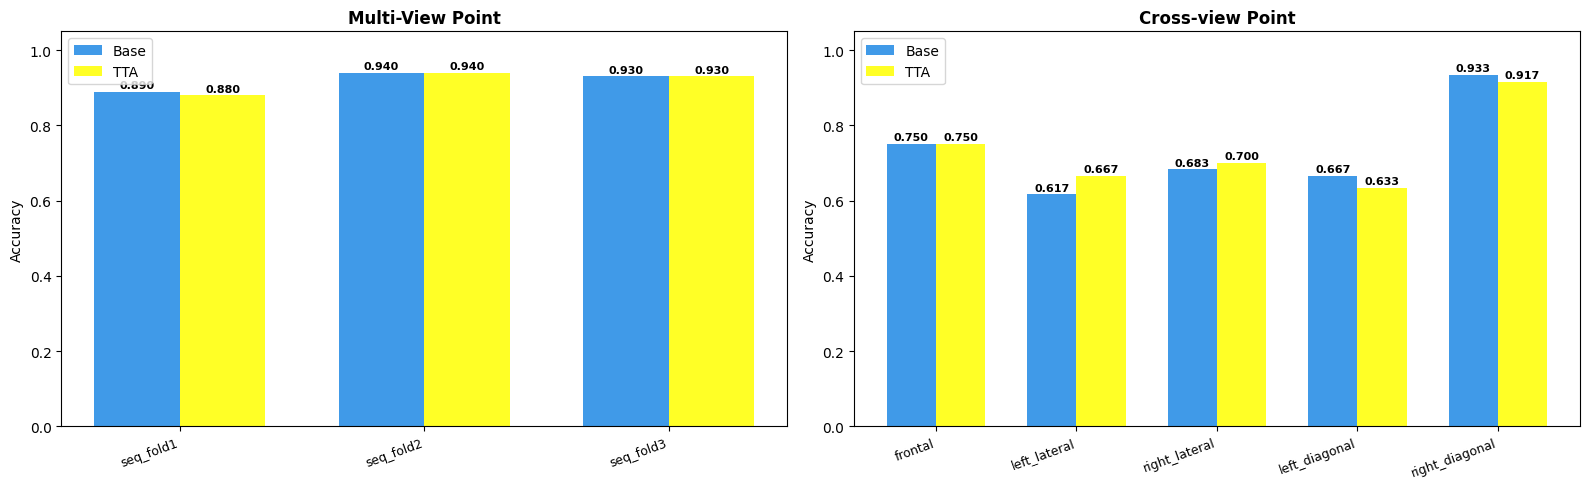

In [ ]:
# Accuracy comparison: Base vs TTA
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

for ax, results, title in [
    (ax1, seq_results, 'Multi-View Point'),
    (ax2, dir_results, 'Cross-view Point')
]:
    names  = [r['name'] for r in results]
    base   = [r['best_acc'] for r in results]
    tta    = [r['tta_acc']  for r in results]
    x      = np.arange(len(names))
    w      = 0.35
    b1 = ax.bar(x-w/2, base, w, label='Base', color='#1E88E5', alpha=0.85)
    b2 = ax.bar(x+w/2, tta,  w, label='TTA',  color='#FFFF00', alpha=0.85)

    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha='right', fontsize=9)
    ax.set_ylim(0, 1.05); ax.set_ylabel('Accuracy'); ax.set_title(title, fontweight='bold')
    ax.legend()
    for bar in list(b1)+list(b2):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{bar.get_height():.3f}', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('v3_base_vs_tta.png', dpi=120, bbox_inches='tight')
plt.show()

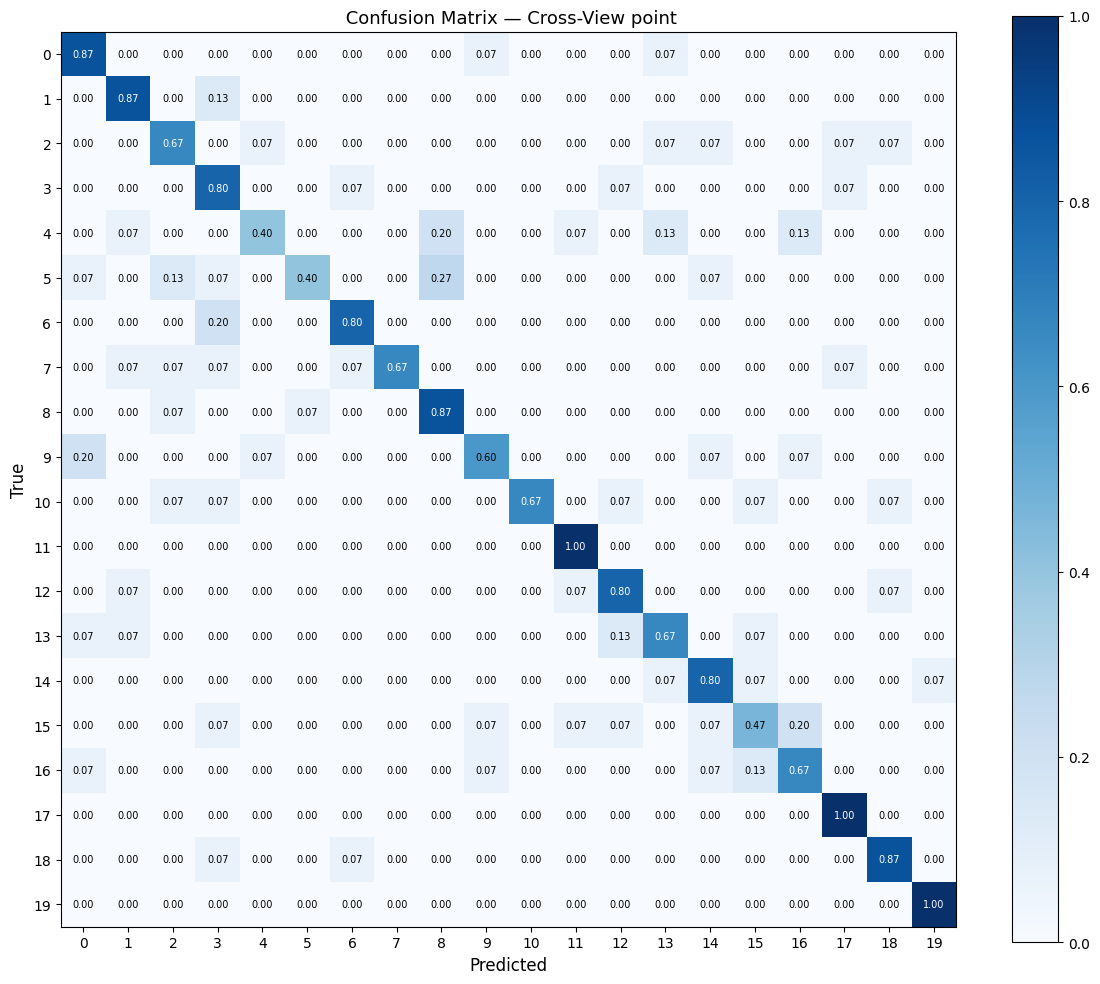

In [ ]:
all_dir_labels = []
all_dir_preds  = []
for r in dir_results:
    all_dir_labels.extend(r['labels'])
    all_dir_preds.extend(r['preds'])

y_t = np.array(all_dir_labels)
y_p = np.array(all_dir_preds)

cm = confusion_matrix(y_t, y_p)
cm_n = cm.astype('float') / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm_n, cmap='Blues', vmin=0, vmax=1)
plt.colorbar(im, ax=ax)
ax.set_xticks(np.arange(num_classes)); ax.set_yticks(np.arange(num_classes))
ax.set_xlabel('Predicted', fontsize=12); ax.set_ylabel('True', fontsize=12)
ax.set_title(' Confusion Matrix — Cross-View point', fontsize=13)
for i in range(cm_n.shape[0]):
    for j in range(cm_n.shape[1]):
        ax.text(j,i,f'{cm_n[i,j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if cm_n[i,j]>0.6 else 'black')
plt.tight_layout()
plt.savefig('v3_direction_aggregated_confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

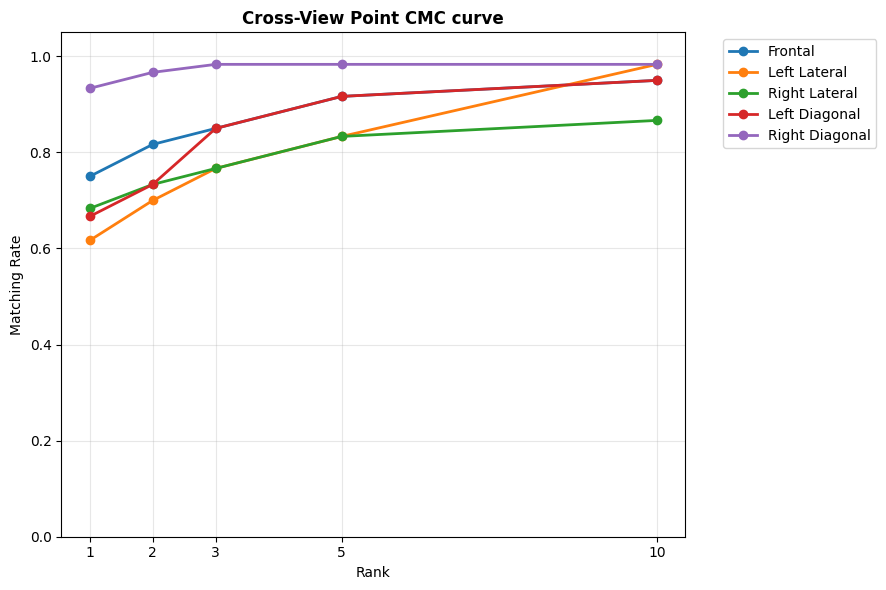

In [ ]:
dir_cmc_results = {}
ranks = [1, 2, 3, 5, 10]

for r in dir_results:
    # Find the corresponding fold in original data (if needed, though here we use test_d from prepare_fold)
    # The 'name' of dir_results corresponds directly to the direction string
    test_direction = r['name']

    # Re-prepare the fold to get test_d for current direction
    fold_raw = {
        'train': [x for x in processed_data if x['direction'] != test_direction],
        'test':  [x for x in processed_data if x['direction'] == test_direction]
    }
    _, test_d = prepare_fold(fold_raw)

    model_dir = PersonIDv3(num_classes, embed_dim=EMBED_DIM).to(device)
    model_dir.load_state_dict(r['best_state'])
    model_dir.eval()

    ds_dir = PersonIDDataset(test_d, label_map, runtime_aug=False)
    loader_dir = DataLoader(ds_dir, batch_size=32, shuffle=False)

    all_logits = []
    all_true = []

    with torch.no_grad():
        for feat, canon, anthro, gait, shape, lbl in loader_dir:
            logits, _, _ = model_dir(
                feat.to(device),
                canon.to(device),
                anthro.to(device),
                gait.to(device),
                shape.to(device)
            )
            all_logits.append(logits.cpu().numpy())
            all_true.append(lbl.numpy())

    all_logits = np.concatenate(all_logits, axis=0)
    all_true   = np.concatenate(all_true, axis=0)

    sorted_idx = np.argsort(-all_logits, axis=1)
    cmc_scores = [
        np.mean([all_true[i] in sorted_idx[i, :rk] for i in range(len(all_true))])
        for rk in ranks
    ]

    dir_cmc_results[r['name']] = cmc_scores
    del model_dir

plt.figure(figsize=(9, 6))
for name, scores in dir_cmc_results.items():
    plt.plot(ranks, scores, marker='o', linewidth=2, label=name.replace('_', ' ').title())

plt.xlabel('Rank')
plt.ylabel('Matching Rate')
plt.title('Cross-View Point CMC curve', fontweight='bold')
plt.xticks(ranks)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('v3_direction_cmc_allfolds.png', dpi=120, bbox_inches='tight')
plt.show()

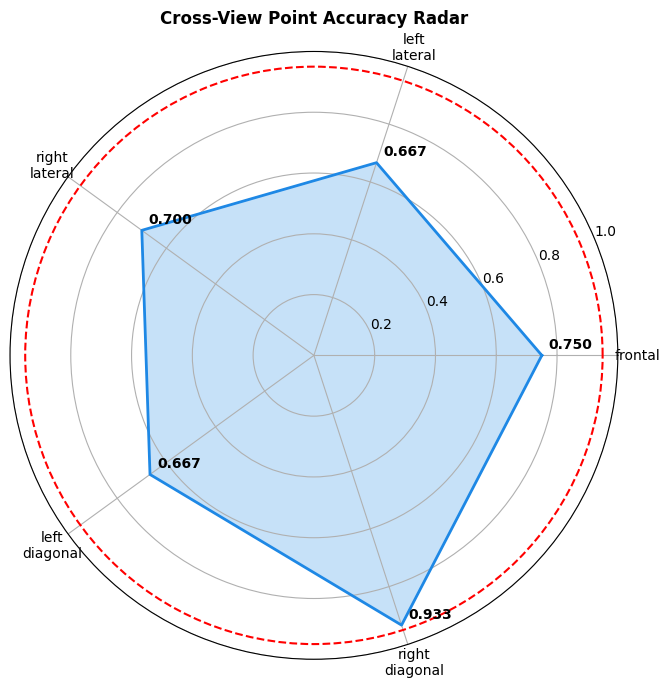

In [ ]:
# Direction radar
dir_labels = [r['name'] for r in dir_results]
dir_vals   = [r['final_acc'] for r in dir_results]
N = len(dir_labels)
ang = np.linspace(0,2*np.pi,N,endpoint=False).tolist()
v2 = dir_vals + dir_vals[:1]; a2 = ang + ang[:1]

fig, ax = plt.subplots(figsize=(7,7), subplot_kw=dict(polar=True))
ax.plot(a2, v2, lw=2, color='#1E88E5')
ax.fill(a2, v2, alpha=0.25, color='#1E88E5')
ax.set_xticks(ang)
ax.set_xticklabels([l.replace('_','\n') for l in dir_labels], fontsize=10)
ax.set_ylim(0,1)
ax.axhline(0.95, color='red', lw=1.5, ls='--')
ax.set_title('Cross-View Point Accuracy Radar', pad=20, fontweight='bold')
for a,v in zip(ang,dir_vals):
    ax.annotate(f'{v:.3f}',xy=(a,v),textcoords='offset points',
                xytext=(5,5),fontsize=10,fontweight='bold')
plt.tight_layout()
plt.savefig('v3_direction_radar.png', dpi=120, bbox_inches='tight')
plt.show()

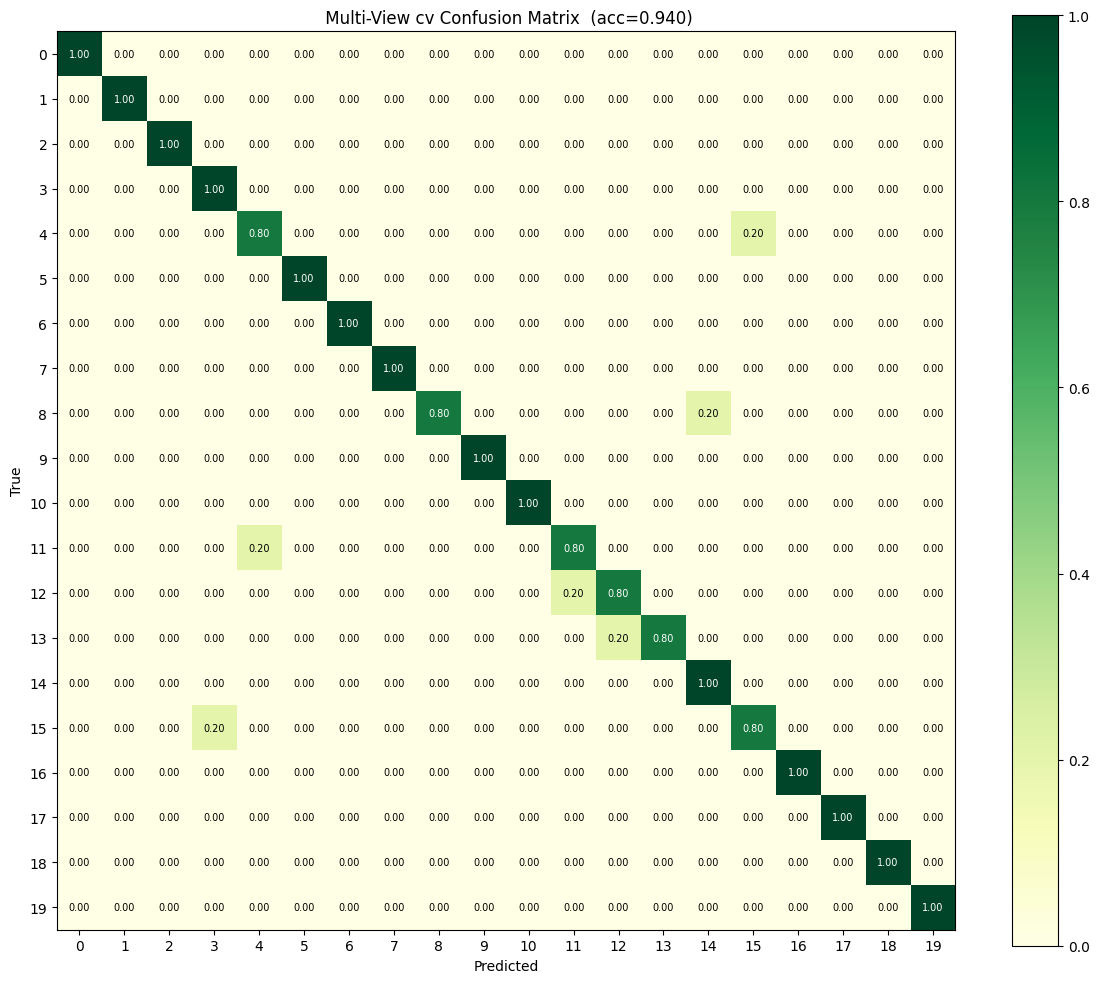

In [ ]:
# Confusion Matrix — Best Sequence Fold Only
best_seq = max(seq_results, key=lambda r: r['final_acc'])
y_t = np.array(best_seq['labels'])
y_p = np.array(best_seq['preds'])

cm = confusion_matrix(y_t, y_p)
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm_n, cmap='YlGn', vmin=0, vmax=1)
plt.colorbar(im, ax=ax)

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f' Multi-View cv Confusion Matrix  (acc={best_seq['final_acc']:.3f})')

for i in range(cm_n.shape[0]):
    for j in range(cm_n.shape[1]):
        ax.text(j, i, f'{cm_n[i, j]:.2f}',
                ha='center', va='center', fontsize=7,
                color='white' if cm_n[i, j] > 0.6 else 'black')

plt.tight_layout()
plt.savefig('v3_sequence_confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

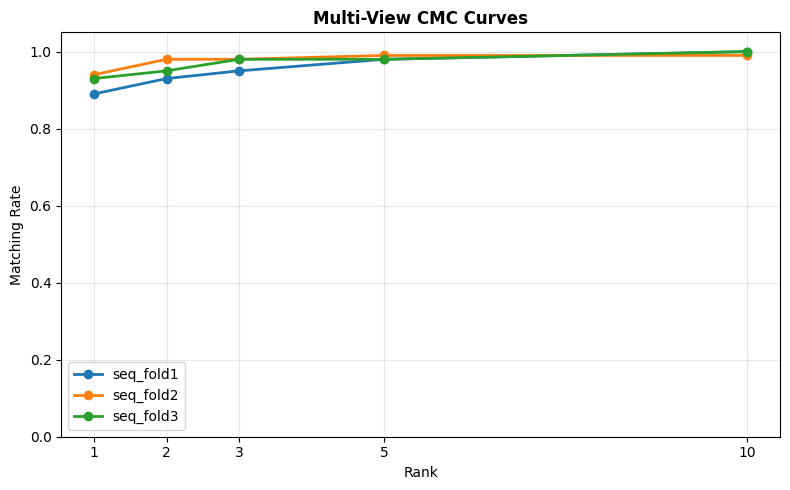

In [ ]:
# Sequence CMC Curves — All 3 Sequence Folds
seq_cmc_results = {}
ranks = [1, 2, 3, 5, 10]

for r in seq_results:
    fi = int(r['name'][-1]) - 1
    _, test_d = prepare_fold(seq_folds_raw[fi])

    model_seq = PersonIDv3(num_classes, embed_dim=EMBED_DIM).to(device)
    model_seq.load_state_dict(r['best_state'])
    model_seq.eval()

    ds_seq = PersonIDDataset(test_d, label_map, runtime_aug=False)
    loader_seq = DataLoader(ds_seq, batch_size=32, shuffle=False)

    all_logits = []
    all_true = []

    with torch.no_grad():
        for feat, canon, anthro, gait, shape, lbl in loader_seq:
            logits, _, _ = model_seq(
                feat.to(device),
                canon.to(device),
                anthro.to(device),
                gait.to(device),
                shape.to(device)
            )
            all_logits.append(logits.cpu().numpy())
            all_true.append(lbl.numpy())

    all_logits = np.concatenate(all_logits, axis=0)
    all_true   = np.concatenate(all_true, axis=0)

    sorted_idx = np.argsort(-all_logits, axis=1)
    cmc_scores = [
        np.mean([all_true[i] in sorted_idx[i, :rk] for i in range(len(all_true))])
        for rk in ranks
    ]

    seq_cmc_results[r['name']] = cmc_scores
    del model_seq

plt.figure(figsize=(8, 5))
for name, scores in seq_cmc_results.items():
    plt.plot(ranks, scores, marker='o', linewidth=2, label=name)

plt.xlabel('Rank')
plt.ylabel('Matching Rate')
plt.title('Multi-View CMC Curves', fontweight='bold')
plt.xticks(ranks)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('v3_sequence_cmc_allfolds.png', dpi=120, bbox_inches='tight')
plt.show()

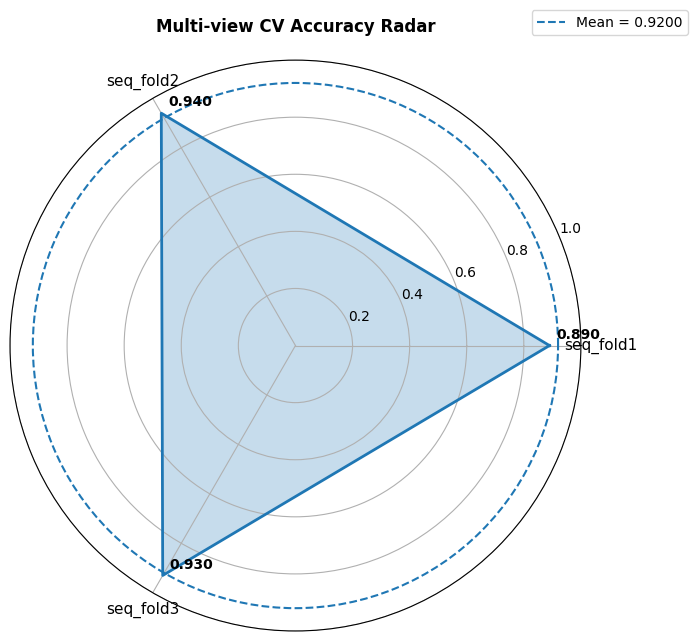

In [ ]:
# Sequence 3-Fold Radar Chart
seq_labels = [r['name'] for r in seq_results]
seq_vals   = [r['final_acc'] for r in seq_results]

N = len(seq_labels)
ang = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
a2 = ang + ang[:1]
v2 = seq_vals + seq_vals[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.plot(a2, v2, linewidth=2)
ax.fill(a2, v2, alpha=0.25)

ax.set_xticks(ang)
ax.set_xticklabels(seq_labels, fontsize=11)
ax.set_ylim(0, 1)
ax.axhline(np.mean(seq_vals), linestyle='--', linewidth=1.5,
           label=f'Mean = {np.mean(seq_vals):.4f}')

for a, v in zip(ang, seq_vals):
    ax.annotate(f'{v:.3f}', xy=(a, v), textcoords='offset points',
                xytext=(5, 5), fontsize=10, fontweight='bold')

ax.set_title('Multi-view CV Accuracy Radar', pad=20, fontweight='bold')
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1))
plt.tight_layout()
plt.savefig('v3_sequence_radar.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# Classification report — best fold
target_names = [f'Subject_{sid}' for sid in sorted(label_map.keys())]
print('='*70)
print(f'CLASSIFICATION REPORT — {best_seq["name"]}  (acc={best_seq["final_acc"]:.4f})')
print('='*70)
print(classification_report(best_seq['labels'], best_seq['preds'],
                             target_names=target_names, digits=4))

CLASSIFICATION REPORT — seq_fold2  (acc=0.9400)
              precision    recall  f1-score   support

   Subject_1     1.0000    1.0000    1.0000         5
   Subject_2     1.0000    1.0000    1.0000         5
   Subject_3     1.0000    1.0000    1.0000         5
   Subject_4     0.8333    1.0000    0.9091         5
   Subject_7     0.8000    0.8000    0.8000         5
   Subject_8     1.0000    1.0000    1.0000         5
   Subject_9     1.0000    1.0000    1.0000         5
  Subject_11     1.0000    1.0000    1.0000         5
  Subject_12     1.0000    0.8000    0.8889         5
  Subject_13     1.0000    1.0000    1.0000         5
  Subject_14     1.0000    1.0000    1.0000         5
  Subject_15     0.8000    0.8000    0.8000         5
  Subject_16     0.8000    0.8000    0.8000         5
  Subject_17     1.0000    0.8000    0.8889         5
  Subject_19     0.8333    1.0000    0.9091         5
  Subject_20     0.8000    0.8000    0.8000         5
  Subject_21     1.0000    1.0000

In [ ]:
print('\n   Sequence 3-Fold CV (Base | TTA):')
for r in seq_results:
    flag = '*' if r['final_acc'] >= 0.95 else '  '
    print(f'    {flag} {r["name"]:12s}: {r["best_acc"]:.4f} base | {r["tta_acc"]:.4f} TTA → Final: {r["final_acc"]:.4f}')
print(f'    Mean: {np.mean(seq_accs):.4f}  Std: {np.std(seq_accs):.4f}')

print('\n  Direction 5-Fold CV (Base | TTA):')
for r in dir_results:
    flag = '*' if r['final_acc'] >= 0.95 else '  '
    print(f'    {flag} {r["name"]:20s}: {r["best_acc"]:.4f} base | {r["tta_acc"]:.4f} TTA → Final: {r["final_acc"]:.4f}')
print(f'    Mean: {np.mean(dir_accs):.4f}  Std: {np.std(dir_accs):.4f}')

overall = np.mean(seq_accs + dir_accs)
print(f'\n   Overall Mean Accuracy: {overall:.4f}')


   Sequence 3-Fold CV (Base | TTA):
       seq_fold1   : 0.8900 base | 0.8800 TTA → Final: 0.8900
       seq_fold2   : 0.9400 base | 0.9400 TTA → Final: 0.9400
       seq_fold3   : 0.9300 base | 0.9300 TTA → Final: 0.9300
    Mean: 0.9200  Std: 0.0216

  Direction 5-Fold CV (Base | TTA):
       frontal             : 0.7500 base | 0.7500 TTA → Final: 0.7500
       left_lateral        : 0.6167 base | 0.6667 TTA → Final: 0.6667
       right_lateral       : 0.6833 base | 0.7000 TTA → Final: 0.7000
       left_diagonal       : 0.6667 base | 0.6333 TTA → Final: 0.6667
       right_diagonal      : 0.9333 base | 0.9167 TTA → Final: 0.9333
    Mean: 0.7433  Std: 0.0998

   Overall Mean Accuracy: 0.8096


In [ ]:
from google.colab import files

png_files = [
    'v3_base_vs_tta.png',
    'v3_direction_cmc_allfolds.png',
    'v3_direction_radar.png',
    'v3_sequence_confusion_matrix.png',
    'v3_sequence_cmc_allfolds.png',
    'v3_sequence_radar.png',
    'v3_direction_aggregated_confusion_matrix.png'
]

for f in png_files:
    try:
        files.download(f)
    except:
        print(f"Not found: {f}")

Not found: v3_training_curves.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Not found: v3_confusion_matrix.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (7 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>